# TuniShop — Machine learning 02. Prévision des ventes

**Auteure :** Sarra Abdeljaouad · **Phase :** machine learning · **Source :** TuniShop_DWH (vues `bi`), via `05_Data/features` · **Découpage :** apprentissage 2023-2024, test 2025

## Objectif

Prévoir le **CA TTC mensuel de chaque catégorie** pour 2025, à partir de 2023-2024 seulement, et **battre le modèle de référence** (Holt-Winters).

| Modèle | Rôle | Idée |
|---|---|---|
| Naïf saisonnier | référence simple | 2025 = même mois de 2024 |
| Naïf × croissance | référence simple | même mois de 2024 × croissance 2024/2023 de la catégorie |
| **Holt-Winters** | **référence statistique** | tendance + saisonnalité de 12 mois, par catégorie |
| Régression « mois » | ML | log(CA) = tendance + catégorie + 12 mois de l'année |
| **Régression « calendrier »** | **ML** | log(CA) = tendance + catégorie + **part des jours de Ramadan, pré-Aïd, Black Friday, soldes...** |

**Pourquoi le calendrier ?** L'EDA a montré que les pics suivent le Ramadan et l'Aïd, qui avancent d'environ 11 jours par an : un modèle qui raisonne « par mois » (Holt-Winters, régression « mois ») place les pics au mauvais endroit. Le calendrier de `v_dim_date` est connu à l'avance : on peut l'utiliser pour prévoir.

**Mesures :** MAPE (erreur relative moyenne), WAPE (erreur totale / CA total), biais (sur- ou sous-estimation), sur le total et par catégorie.

## 0. Préparation

In [1]:
# --- Bibliothèques
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

# --- Module commun du projet (dossier 00_Commun)
sys.path.insert(0, "../00_Commun")
from tunishop_analytics import config as cfg, chargement, features, temporal_split, validation, publication

warnings.filterwarnings("ignore")
cfg.appliquer_style()
sql = chargement.requete                       # sql("SELECT ...") -> exécuté par SQL Server
pd.set_option("display.float_format", lambda v: f"{v:,.3f}".replace(",", " "))

def montrer(nom):
    """Enregistre la figure en cours dans 06_Exports/Figures/<nom>.png, puis l'affiche."""
    cfg.sauver_figure(plt.gcf(), nom)
    plt.show()

for dossier in (cfg.DOSSIER_MODELES, cfg.DOSSIER_PREDICTIONS):
    dossier.mkdir(parents=True, exist_ok=True)

from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from statsmodels.tsa.holtwinters import ExponentialSmoothing

In [2]:
chargement.ouvrir_connexion()

ventes = features.lire("ml_ventes")
app, test = ventes[ventes["periode"] == "apprentissage"], ventes[ventes["periode"] == "test"]
categories = sorted(ventes["categorie"].unique())
print(f"{ventes['categorie'].nunique()} catégories x {ventes['mois'].nunique()} mois ; apprentissage {app['mois'].min():%m/%Y}-{app['mois'].max():%m/%Y}, test {test['mois'].min():%m/%Y}-{test['mois'].max():%m/%Y}")

# 🔗 Contrôle SQL direct : CA TTC 2025 des lignes abouties, calculé par SQL Server
ca_2025_sql = chargement.valeur("""
    SELECT SUM(v.montant_ttc) FROM bi.v_fact_ventes v
    JOIN bi.v_dim_statut_commande s ON s.statut_commande_sk = v.statut_commande_sk
    JOIN bi.v_dim_date d ON d.date_sk = v.date_commande_sk
    WHERE s.famille_statut = 'aboutie' AND v.produit_sk > 0 AND d.annee = 2025""")
print(f"CA TTC 2025 — SQL : {float(ca_2025_sql):,.3f} ; jeu de données : {test['ca_ttc'].sum():,.3f}".replace(",", " "))

Connecté à TuniShop_DWH sur localhost (pilote : ODBC Driver 17 for SQL Server)
9 catégories x 36 mois ; apprentissage 01/2023-12/2024, test 01/2025-12/2025
CA TTC 2025 — SQL : 7 068 897.400 ; jeu de données : 7 068 897.400


## 1. Les modèles de référence

In [3]:
def pivot(t, col="ca_ttc"):
    return t.pivot(index="mois", columns="categorie", values=col)

reel = pivot(test)
hist = pivot(app)
previsions = {}

# Naïf saisonnier : chaque mois de 2025 = le même mois de 2024
previsions["Naïf saisonnier"] = pd.DataFrame(hist.loc["2024"].values, index=reel.index, columns=hist.columns)
# Naïf x croissance : même mois de 2024 x (CA 2024 / CA 2023) de la catégorie
croissance = hist.loc["2024"].sum() / hist.loc["2023"].sum()
previsions["Naïf × croissance"] = previsions["Naïf saisonnier"] * croissance
# Holt-Winters : tendance additive, saisonnalité multiplicative de 12 mois, une série par catégorie
hw = {}
for c in categories:
    serie = hist[c].asfreq("MS")
    hw[c] = ExponentialSmoothing(serie, trend="add", seasonal="mul", seasonal_periods=12,
                                 initialization_method="estimated").fit().forecast(12).values
previsions["Holt-Winters (référence)"] = pd.DataFrame(hw, index=reel.index)
croissance.rename("croissance 2024/2023").to_frame().T

categorie,Beauté & Santé,Bébé & Enfants,Fournitures & Livres,Maison & Cuisine,Mode,Sport & Loisirs,Électroménager,Électronique & High-Tech,Épicerie fine
croissance 2024/2023,1.381,1.675,1.788,1.331,1.605,1.354,1.520,1.452,1.262


## 2. Les modèles de machine learning (régression Ridge)

On modélise le **logarithme** du CA : les effets deviennent multiplicatifs (« le Ramadan augmente le CA de x % ») et la tendance se prolonge en croissance relative. La régression **Ridge** est une régression linéaire avec une pénalité `alpha` qui évite des coefficients extrêmes (seulement 216 lignes d'apprentissage).

**Choix d'`alpha` sans toucher au test :** on apprend sur janvier 2023 – juin 2024 et on mesure l'erreur sur juillet – décembre 2024 (**validation**), puis on réapprend sur tout 2023-2024 avec le meilleur `alpha`.

In [4]:
mois_cols = [f"mois_{m}" for m in range(1, 13)]

def variables(t, version):
    X = pd.get_dummies(t["categorie"], dtype=float).reindex(columns=categories, fill_value=0)
    X["t"] = t["t"].values
    if version == "mois":
        X = X.join(pd.get_dummies(t["mois"].dt.month, prefix="mois", dtype=float).reindex(columns=mois_cols, fill_value=0))
    else:
        X = X.join(t[features.CALENDRIER])
    return X

def mape_total(t, prevu):
    tot = t.assign(p=prevu).groupby("mois")[["ca_ttc", "p"]].sum()
    return float((abs(tot["p"] - tot["ca_ttc"]) / tot["ca_ttc"]).mean())

choix = []
valid_app, valid_val = app[app["mois"] <= "2024-06-01"], app[app["mois"] > "2024-06-01"]
for version in ["mois", "calendrier"]:
    for alpha in [0.03, 0.1, 0.3, 1.0, 3.0]:
        m = Ridge(alpha=alpha).fit(variables(valid_app, version), np.log(valid_app["ca_ttc"]))
        choix.append({"version": version, "alpha": alpha,
                      "MAPE validation (S2 2024)": mape_total(valid_val, np.exp(m.predict(variables(valid_val, version))))})
choix = pd.DataFrame(choix)
meilleurs = choix.loc[choix.groupby("version")["MAPE validation (S2 2024)"].idxmin()].set_index("version")

modeles = {}
for version in ["mois", "calendrier"]:
    alpha = meilleurs.loc[version, "alpha"]
    modeles[version] = Ridge(alpha=alpha).fit(variables(app, version), np.log(app["ca_ttc"]))
    p = np.exp(modeles[version].predict(variables(test, version)))
    previsions[f"Ridge « {version} »"] = test.assign(p=p).pivot(index="mois", columns="categorie", values="p")
cfg.exporter_table(choix, "ML02_choix_alpha", index=False)
meilleurs

Publication : connecté à TuniShop_ANALYTICS sur localhost
  ✔ ana.ml02_choix_alpha                             10 lignes


,alpha,MAPE validation (S2 2024)
version,,
calendrier,0.100,0.084
mois,0.030,0.104


> **Lecture.** Sur la validation (2nd semestre 2024), la version **calendrier** fait mieux que la version « mois » (MAPE 8,4 % contre 10,4 %), avec une pénalité `alpha` = 0,1. C'est sur cette base, et non sur le test, que la version calendrier est retenue.

## 3. Résultats sur 2025 (test)

In [5]:
lignes = []
for nom, prev in previsions.items():
    prev = prev[categories]
    tot = validation.metriques_regression(reel[categories].sum(axis=1), prev.sum(axis=1))
    par_cat = [validation.metriques_regression(reel[c], prev[c])["MAPE"] for c in categories]
    lignes.append({"cas": "ventes", "modele": nom,
                   "role": "référence" if "Naïf" in nom or "Holt" in nom else "candidat",
                   "MAPE_total": tot["MAPE"], "WAPE_total": tot["WAPE"], "biais_total": tot["biais"],
                   "MAPE_moyen_categories": float(np.mean(par_cat))})
resultats = pd.DataFrame(lignes).sort_values("MAPE_total").reset_index(drop=True)
reference = resultats.loc[resultats["modele"] == "Holt-Winters (référence)", "MAPE_total"].iloc[0]
resultats["gain_vs_reference"] = 1 - resultats["MAPE_total"] / reference
# Modèle retenu : la version de Ridge la meilleure sur la VALIDATION (2nd semestre 2024), pas sur le test
RETENU = f"Ridge « {meilleurs['MAPE validation (S2 2024)'].idxmin()} »"
resultats["MAPE_validation"] = resultats["modele"].map({f"Ridge « {v} »": r["MAPE validation (S2 2024)"] for v, r in meilleurs.iterrows()})
resultats["retenu"] = resultats["modele"] == RETENU
cfg.exporter_table(resultats, "ML_metriques_ventes", index=False)
resultats

  ✔ ana.ml_metriques_ventes                           5 lignes


,cas,modele,role,MAPE_total,WAPE_total,biais_total,MAPE_moyen_categories,gain_vs_reference,MAPE_validation,retenu
0,ventes,Ridge « calendrier »,candidat,0.095,0.093,0.027,0.170,0.375,0.084,True
1,ventes,Holt-Winters (référence),référence,0.153,0.160,-0.080,0.212,0.000,NaN,False
2,ventes,Ridge « mois »,candidat,0.162,0.157,0.028,0.224,-0.059,0.104,False
3,ventes,Naïf × croissance,référence,0.167,0.158,0.046,0.230,-0.092,NaN,False
4,ventes,Naïf saisonnier,référence,0.278,0.297,-0.297,0.321,-0.821,NaN,False


> **Lecture.** Sur 2025, la **régression « calendrier »** se trompe de **9,5 %** en moyenne sur le CA total mensuel, contre **15,3 %** pour Holt-Winters : **37,5 % d'erreur en moins** que la référence, avec un biais faible (+2,7 % contre -8,0 %). La régression « mois », qui a les mêmes ingrédients sauf le calendrier, fait **moins bien** que Holt-Winters (16,2 %) : tout le gain vient du **calendrier lunaire**, pas du simple fait d'utiliser du machine learning. Par catégorie, l'erreur moyenne passe de 21,2 % à 17,0 %.

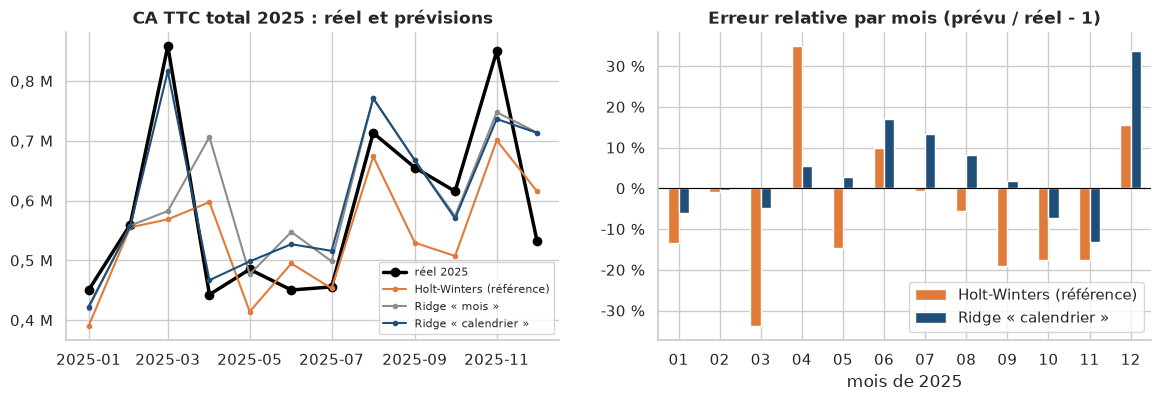

In [6]:
# Réel et prévisions du CA total, mois par mois en 2025
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(reel.index, reel.sum(axis=1), color="black", lw=2.5, marker="o", label="réel 2025")
for nom, coul in [("Holt-Winters (référence)", cfg.ORANGE), ("Ridge « mois »", cfg.GRIS), (RETENU, cfg.BLEU)]:
    axes[0].plot(reel.index, previsions[nom][categories].sum(axis=1), marker=".", color=coul, label=nom)
axes[0].set_title("CA TTC total 2025 : réel et prévisions"); cfg.format_millions(axes[0]); axes[0].legend(fontsize=8)
erreurs = pd.DataFrame({nom: previsions[nom][categories].sum(axis=1) / reel.sum(axis=1) - 1
                        for nom in ["Holt-Winters (référence)", RETENU]})
erreurs.index = erreurs.index.strftime("%m")
erreurs.plot.bar(ax=axes[1], color=[cfg.ORANGE, cfg.BLEU], rot=0)
axes[1].axhline(0, color="black", lw=0.8); axes[1].set_title("Erreur relative par mois (prévu / réel - 1)")
cfg.format_pourcent(axes[1]); axes[1].set_xlabel("mois de 2025")
montrer("ML02_1_prevision_2025")

> **Lecture.** Le graphique montre d'où vient le gain : en **mars 2025**, mois du Ramadan et du pré-Aïd, Holt-Winters sous-estime de **33 %** puis surestime avril de **35 %**, parce qu'il place le pic à la date de 2024 ; la régression calendrier reste à -5 % et +5 %. Son point faible est **décembre** (+34 %) : elle attend un effet « fin d'année » plus fort que celui observé en 2025.

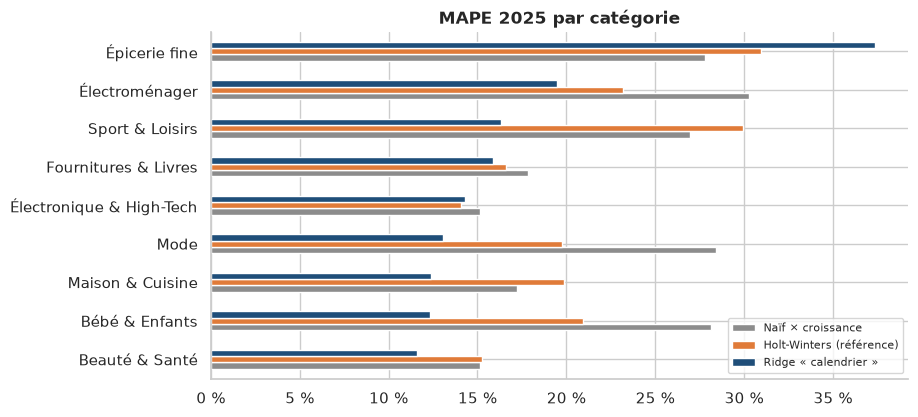

  ✔ ana.ml02_mape_categories                          9 lignes


,Naïf × croissance,Holt-Winters (référence),Ridge « calendrier »
Beauté & Santé,0.152,0.152,0.116
Bébé & Enfants,0.282,0.210,0.123
Fournitures & Livres,0.179,0.166,0.159
Maison & Cuisine,0.172,0.199,0.124
Mode,0.284,0.198,0.131
Sport & Loisirs,0.269,0.299,0.163
Électroménager,0.303,0.232,0.195
Électronique & High-Tech,0.151,0.141,0.143
Épicerie fine,0.278,0.309,0.374


In [7]:
# Erreur par catégorie : référence contre modèle retenu
par_cat = pd.DataFrame({nom: {c: validation.metriques_regression(reel[c], previsions[nom][c])["MAPE"] for c in categories}
                        for nom in ["Naïf × croissance", "Holt-Winters (référence)", RETENU]})
ax = par_cat.sort_values(RETENU).plot.barh(figsize=(9, 4.5), color=[cfg.GRIS, cfg.ORANGE, cfg.BLEU])
ax.set_title("MAPE 2025 par catégorie"); cfg.format_pourcent(ax, "x"); ax.legend(fontsize=8)
montrer("ML02_2_mape_categories")
cfg.exporter_table(par_cat, "ML02_mape_categories")
par_cat

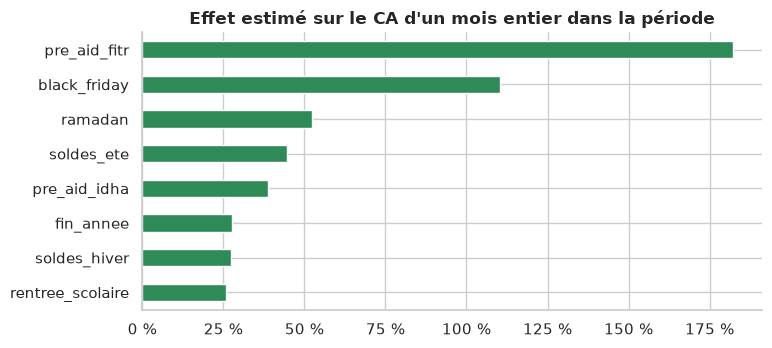

Tendance : +3.4% par mois, soit +49% par an


,effet
rentree_scolaire,0.258
soldes_hiver,0.275
fin_annee,0.276
pre_aid_idha,0.388
soldes_ete,0.446
ramadan,0.523
black_friday,1.102
pre_aid_fitr,1.821


In [8]:
# Ce que le modèle a appris du calendrier : effet multiplicatif d'un mois entièrement dans chaque période
coef = pd.Series(modeles["calendrier"].coef_, index=variables(app, "calendrier").columns)
effets = (np.exp(coef[features.CALENDRIER]) - 1).rename(lambda c: c.replace("part_jours_", "")).sort_values()
ax = effets.plot.barh(color=[cfg.ROUGE if v < 0 else cfg.VERT for v in effets], figsize=(8, 3.6))
ax.set_title("Effet estimé sur le CA d'un mois entier dans la période"); cfg.format_pourcent(ax, "x")
montrer("ML02_3_effets_calendrier")
print(f"Tendance : {np.exp(coef['t']) - 1:+.1%} par mois, soit {np.exp(12 * coef['t']) - 1:+.0%} par an")
effets.to_frame("effet")

> **Lecture.** Le modèle chiffre l'effet d'un mois **entièrement** dans chaque période : **pré-Aïd el-Fitr +182 %**, **Black Friday +110 %**, Ramadan +52 %, soldes d'été +45 %, pré-Aïd el-Idha +39 %, soldes d'hiver et fin d'année +28 %, rentrée +26 %, sur une tendance de **+3,4 % par mois** (+49 % par an). Ces chiffres reprennent ceux de l'EDA (Black Friday ×2,8 par jour, pré-Aïd ×1,8, Ramadan +42 %) ; ils sont estimés sur peu d'occurrences (2 ans), donc à prendre comme des ordres de grandeur.

## 4. Sauvegarde et prévision 2026 (🔗 calendrier lu dans le DWH)

Le modèle retenu est sauvegardé tel qu'appris sur 2023-2024 (celui qui a été évalué). Pour l'usage réel, on le **réapprend sur 2023-2025** et on prévoit 2026 : le calendrier 2026 (Ramadan, Aïd, Black Friday...) est lu directement dans la vue `bi.v_dim_date` du DWH. Un garde-fou vérifie d'abord que ce calendrier est bien renseigné.

  ✔ ana.ml_pred_ventes_2025                         108 lignes
  ✔ ana.ml_pred_ventes_2026                         108 lignes


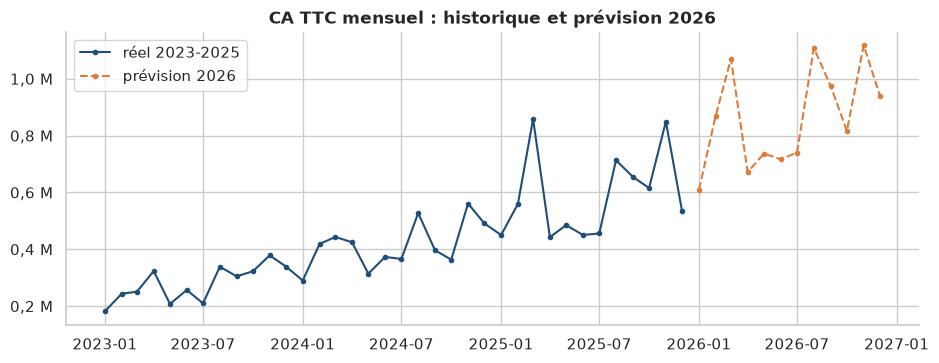

CA TTC prévu en 2026 : 10.37 M DT (2025 : 7.07 M DT)


In [9]:
version = "calendrier" if "calendrier" in RETENU else "mois"
alpha = meilleurs.loc[version, "alpha"]
joblib.dump({"modele": modeles[version], "version": version, "alpha": alpha, "categories": categories,
             "variables": list(variables(app, version).columns), "appris_sur": "2023-2024"},
            cfg.DOSSIER_MODELES / "prevision_ventes_ridge.joblib")

previsions = {k: v[categories].rename_axis(index="mois", columns="categorie") for k, v in previsions.items()}
prev_2025 = previsions[RETENU].stack().rename("prevision").reset_index().merge(
    test[["mois", "categorie", "ca_ttc"]], on=["mois", "categorie"]).rename(columns={"ca_ttc": "reel"})
for nom in ["Naïf saisonnier", "Naïf × croissance", "Holt-Winters (référence)"]:
    prev_2025 = prev_2025.merge(previsions[nom].stack().rename(nom).reset_index(), on=["mois", "categorie"])
cfg.exporter_resultat(prev_2025, cfg.DOSSIER_PREDICTIONS / "ventes_2025_test.parquet")

# Réapprentissage sur 2023-2025 puis prévision 2026 avec le calendrier lu dans le DWH
final = Ridge(alpha=alpha).fit(variables(ventes, version), np.log(ventes["ca_ttc"]))
cal_2026 = features.calendrier_mensuel({"dim_date": chargement.lire_vue("v_dim_date")})
cal_2026 = cal_2026[cal_2026["mois"].dt.year == 2026]
joblib.dump({"modele": final, "version": version, "alpha": alpha, "categories": categories, "appris_sur": "2023-2025"},
            cfg.DOSSIER_MODELES / "prevision_ventes_ridge_2023_2025.joblib")

# Garde-fou : le modèle a besoin du calendrier commercial 2026 (Ramadan, Aïd, Black Friday...) dans v_dim_date
jours_evenements = cal_2026[features.CALENDRIER].sum().sum()
if version == "calendrier" and jours_evenements == 0:
    print("ATTENTION : le calendrier commercial 2026 n'est pas encore renseigné dans bi.v_dim_date "
          "(tous les jours de 2026 sont en période « normale »).\n"
          "Une prévision 2026 sans Ramadan, Aïd ni Black Friday serait fausse : elle n'est pas produite.\n"
          "Action : compléter la colonne periode_commerciale de la dimension date pour 2026 dans le DWH, "
          "puis relancer cette cellule.")
    print(f"Mois de 2026 trouvés dans v_dim_date : {len(cal_2026)} ; mois avec au moins un jour d'événement : "
          f"{int((cal_2026[features.CALENDRIER].sum(axis=1) > 0).sum())}")
else:
    futur = pd.DataFrame([(m, c) for m in cal_2026["mois"] for c in categories], columns=["mois", "categorie"]).merge(cal_2026, on="mois")
    futur["t"] = (futur["mois"].dt.year - 2023) * 12 + futur["mois"].dt.month - 1
    futur["prevision_ca_ttc"] = np.exp(final.predict(variables(futur, version)))
    cfg.exporter_resultat(futur[["mois", "categorie", "prevision_ca_ttc"]], cfg.DOSSIER_PREDICTIONS / "ventes_2026.parquet")
    total_2026 = futur.groupby("mois")["prevision_ca_ttc"].sum()
    fig, ax = plt.subplots(figsize=(11, 3.8))
    hist_tot = ventes.groupby("mois")["ca_ttc"].sum()
    ax.plot(hist_tot.index, hist_tot.values, color=cfg.BLEU, marker="o", ms=3, label="réel 2023-2025")
    ax.plot(total_2026.index, total_2026.values, color=cfg.ORANGE, marker="o", ms=3, ls="--", label="prévision 2026")
    ax.set_title("CA TTC mensuel : historique et prévision 2026"); cfg.format_millions(ax); ax.legend()
    montrer("ML02_4_prevision_2026")
    print(f"CA TTC prévu en 2026 : {total_2026.sum() / 1e6:.2f} M DT (2025 : {test['ca_ttc'].sum() / 1e6:.2f} M DT)")

> **Lecture.** **Prévision 2026.** Le graphique et la ligne « CA TTC prévu en 2026 » sont produits **seulement si** le calendrier commercial 2026 est chargé dans `v_dim_date` (Ramadan, Aïd, Black Friday…). Avec le calendrier chargé (réserve R1 levée), le modèle réappris sur 2023-2025 prévoit **10,37 M DT TTC pour 2026** (7,07 M DT en 2025), en prolongeant la tendance et les pics du calendrier ; la prévision est enregistrée dans `06_Exports/Predictions/ventes_2026.parquet` et publiée dans `ana.ml_pred_ventes_2026`. Sans calendrier, la cellule s'arrête avec un message : une prévision 2026 sans Ramadan, Aïd ni Black Friday serait fausse. Chaque année, il faut ajouter le calendrier de l'année suivante avant de relancer.

## 5. Synthèse

> **Lecture.** **Modèle retenu : régression Ridge « calendrier »**, choisie sur la validation 2024 : MAPE 2025 de **9,5 %** contre 15,3 % pour Holt-Winters (-37,5 %), biais +2,7 %. Le facteur décisif est le **calendrier commercial et lunaire** lu dans le DWH. Modèles et prévisions 2025 : `06_Exports/Modeles/prevision_ventes_ridge*.joblib`, `06_Exports/Predictions/ventes_2025_test.parquet`. Prévision 2026 (calendrier chargé) : **10,37 M DT**, dans `06_Exports/Predictions/ventes_2026.parquet`. Action pour la production : ajouter chaque année le calendrier commercial de l'année suivante dans le DWH.

In [10]:
chargement.fermer_connexion()

Connexion fermée.
